In [67]:
import pandas as pd
import glob
import json
import os

sample_path = f'{os.getcwd()}/../workspace/samples/'

x86_samples = 'x86-gemini-pro'
arm_samples = 'arm-gemini-pro'

def get_rows(path):

    summaries = sorted(glob.glob(f'{path}/*/agent_repair/summary.json'))

    rows = []
    for sample, path in enumerate(summaries):

        with open(path, 'r') as f:
            data = json.load(f)
        
        arch = data['summary']['arch']
        model = data['models']['llm']

        for attempt in data['attempts']:
            rows.append({
            'sample': sample,
            'arch': arch,
            'model': model,
            'attempt': attempt['attempt'],
            'boot_succeeded': attempt['summary']['boot_succeeded'],
            'define': attempt['changes']['define'],
            'undefine': attempt['changes']['undefine'],
            'original_config': f'{os.path.dirname(path)}/../.config',
            'modified_config': f'{os.path.dirname(path)}/attempt_{attempt["attempt"]}/modified.config',
            'edit_distance': data['summary']['edit_distance'],
            'total_constraints': data['summary']['total_constraints'],
            'define': attempt['changes']['define'],
            'undefine': attempt['changes']['undefine'],
        })

    return rows

rows = get_rows(f'{sample_path}/{x86_samples}') + get_rows(f'{sample_path}/{arm_samples}')
df = pd.DataFrame(rows)

print(df.groupby('model')['sample'].nunique())

df.head()

model
gemini-3.1-pro-preview    50
Name: sample, dtype: int64


,sample,arch,model,attempt,boot_succeeded,define,undefine,original_config,modified_config,edit_distance,total_constraints
0,0,x86_64,gemini-3.1-pro-preview,0,no,None,None,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,2629,79
1,0,x86_64,gemini-3.1-pro-preview,1,timeout,[],[CONFIG_KASAN],/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,2629,79
2,0,x86_64,gemini-3.1-pro-preview,2,panic,"[CONFIG_TTY, CONFIG_SERIAL_8250, CONFIG_SERIAL...",[CONFIG_KASAN],/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,2629,79
3,0,x86_64,gemini-3.1-pro-preview,3,timeout,[],"[CONFIG_KASAN, CONFIG_KCSAN]",/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,2629,79
4,0,x86_64,gemini-3.1-pro-preview,4,panic,"[CONFIG_TTY, CONFIG_SERIAL_8250, CONFIG_SERIAL...","[CONFIG_KASAN, CONFIG_KCSAN]",/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,/Users/ryangarfinkel/Documents/UCF/Thesis/KBoo...,2629,79


In [68]:
def parse_config(path):
    with open(path, 'r') as f:
        lines = f.readlines()

    options = set()

    for line in lines:
        if '=' in line:
            options.add(line.strip().split('=')[0])
            
    return options


In [69]:
def select_attempt(group):
    group = group[group['attempt'] > 0].sort_values('attempt')

    for outcome in ['yes', 'maintenance']:
        booted = group[group['boot_succeeded'] == outcome]
        if not booted.empty:
            return booted.iloc[0]

    return group.iloc[-1]

last_attempts = pd.DataFrame([select_attempt(group) for _, group in df.groupby(['arch', 'sample'])]).reset_index(drop=True)

print(len(last_attempts), 'configurations.')
print(last_attempts['boot_succeeded'].value_counts().to_string())
print('Attempts selected for failed configurations:', last_attempts[~last_attempts['boot_succeeded'].isin(['yes', 'maintenance'])]['attempt'].tolist())


100 configurations.
boot_succeeded
yes            92
timeout         5
maintenance     3
Attempts selected for failed configurations: [20, 20, 20, 20, 20]


16572 unique options in the first configs.
8200 options were not removed but included in the first config.
count    8372.000000
mean        0.159398
std         0.196500
min         0.010101
25%         0.054545
50%         0.100000
75%         0.166667
max         1.000000


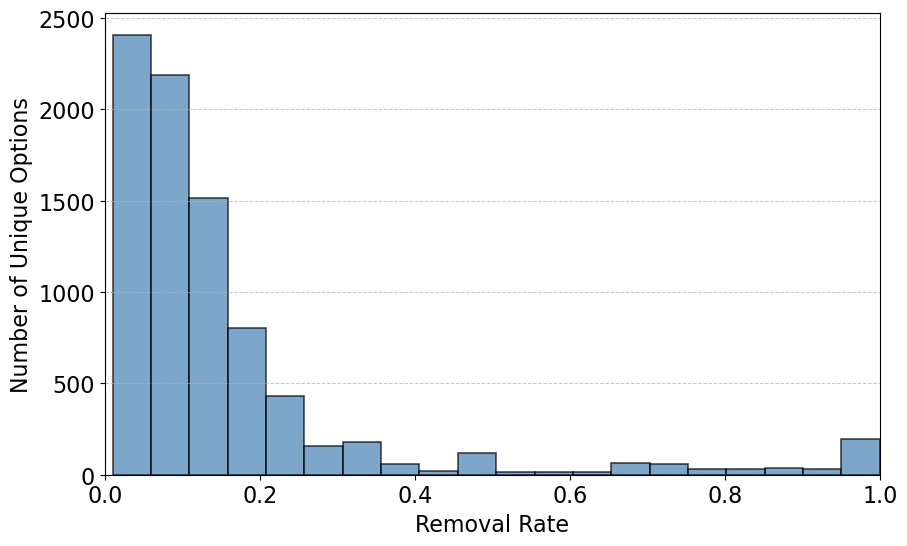

In [70]:
from matplotlib import pyplot as plt
from collections import Counter

in_both = Counter()
in_first = Counter()

for row in last_attempts.itertuples():

    original = parse_config(row.original_config)
    modified = parse_config(row.modified_config)

    in_both.update(original & modified)
    in_first.update(original)

p_removed = pd.Series({
    opt: 1 - (in_both[opt] / in_first[opt]) for opt in in_first
})

print(len(p_removed), 'unique options in the first configs.')
print(len(p_removed[p_removed == 0]), 'options were not removed but included in the first config.')

p_removed = p_removed[p_removed > 0]

print(p_removed.describe().to_string())

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(p_removed[p_removed > 0], color='steelblue', alpha=0.7, edgecolor='black', linewidth=1.2, bins=20)
ax.set_xlim(0, 1)

ax.set_xlabel('Removal Rate', fontsize=16)
ax.set_ylabel('Number of Unique Options', fontsize=16)

ax.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', labelsize=16)

plt.savefig('p-removal-all.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [71]:
print('Number of options removed in each repair attempt:', len(p_removed[p_removed == 1]))
print('Percentage of options removed in each repair attempt:', len(p_removed[p_removed == 1]) / len(p_removed) * 100)

amt = len(p_removed[p_removed <= 0.25])
print('Number of options removed in 25% or fewer of repair attempts:', amt)
print('Percentage of options removed in 25% or fewer of repair attempts:', amt / len(p_removed) * 100)


Number of options removed in each repair attempt: 174
Percentage of options removed in each repair attempt: 2.078356426182513
Number of options removed in 25% or fewer of repair attempts: 7343
Percentage of options removed in 25% or fewer of repair attempts: 87.70903010033445


In [72]:
import random

removed = [opt for opt in in_first if in_first[opt] > in_both[opt] + 5]

sample = random.choice(removed)

print(f'{sample} was in {in_first[sample]} configs and was removed {in_first[sample] - in_both[sample]} times.')

CONFIG_SENSORS_ADM9240 was in 57 configs and was removed 6 times.
